## **About Dataset**

The data sets contains transactions made by credit cards by cardholders. This dataset we have found **492** frauds out of '284,807 transactions'. The dataset is highly unbalanced, the frauds account for **0.172%** of all transactions.
It contains only numerical input variables which are the result of a PCA transformation. **Features V1, V2, … V28** are the principal components obtained with PCA, the only features which have not been transformed with PCA is Time and Amount. Feature Time contains the seconds between each transaction and the first transaction in the dataset. The feature Amount is the transaction Amount, this feature can be used for example-dependant cost-senstive learning. Feature Class is the response variable and it takes value 1 in case of fraud and 0 otherwise.
- **Time** 
Number of seconds elapsed between this transaction and the first transaction in the dataset
- **V1….V28**
may be result of a PCA Dimensionality reduction to protect user identities and sensitive features(v1-v28)
- **Amount**
Transaction amount
- **Class**
The value 1 is for fraudulent transactions, value 0 is for nonfraudulent transactions

In [1]:
### *Download All Necessary Librarires*
!pip install pandas numpy seaborn matplotlib xgboost scikit-learn

### Import All Necessary Librarires

In [27]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, classification_report,  auc, confusion_matrix, roc_curve

## Loading Data By using Pandas as pd 

In [22]:
# Load the dataset
df = pd.read_csv(r"creditcard.csv")
print(df.head(5))

   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.206010   

        V26       V27       V28 

## **Data PreProcessing** 

### for view all detail about Data included Serial number, coloumn name, data type

In [3]:
#Information about data 
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [4]:
# Shape of our data like rows & Coloumns
df.shape

(284807, 31)

In [5]:
# Show Coloumn Names 
df.columns

Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount',
       'Class'],
      dtype='object')

In [6]:
# chect Missing vaue
print(df.isnull().sum())

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64


In [7]:
# Count Fraoud 
fraud_count = df.Class.value_counts()
print(f"No Fraud (0): {fraud_count[0]} \nFraud (1): {fraud_count[1]}")

No Fraud (0): 284315 
Fraud (1): 492


In [8]:
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.168375e-15,3.416908e-16,-1.379537e-15,2.074095e-15,9.604066e-16,1.487313e-15,-5.556467e-16,1.213481e-16,-2.406331e-15,...,1.654067e-16,-3.568593e-16,2.578648e-16,4.473266e-15,5.340915e-16,1.683437e-15,-3.660091e-16,-1.227390e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


In [9]:
# Calculate total amounts for fraud and non-fraud
fraud_amount = df[df['Class'] == 1]['Amount'].sum()
non_fraud_amount = df[df['Class'] == 0]['Amount'].sum()

print(f"Total Fraud Amount (Loss): ${fraud_amount:.2f}")
print(f"Total Non-Fraud Amount: ${non_fraud_amount:.2f}")


Total Fraud Amount (Loss): $60127.97
Total Non-Fraud Amount: $25102462.04


# **Data Visulization**

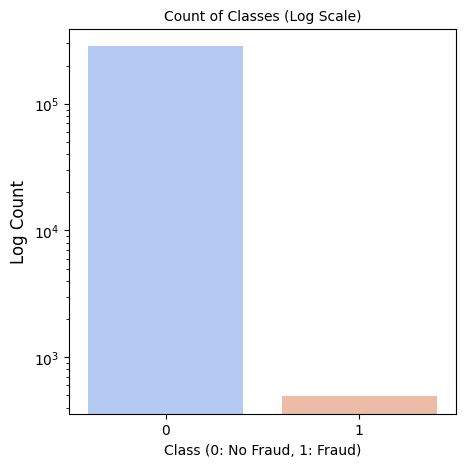

In [10]:
# Create the countplot
plt.figure(figsize=(5, 5))
sns.countplot(data=df, x='Class', palette='coolwarm', log=True)

# Add title and labels
plt.title("Count of Classes (Log Scale)", fontsize=10)
plt.xlabel("Class (0: No Fraud, 1: Fraud)", fontsize=10)
plt.ylabel("Log Count", fontsize=12)

# Show the plot
plt.show()


In [11]:
df.corr()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
Time,1.000000,1.173963e-01,-1.059333e-02,-4.196182e-01,-1.052602e-01,1.730721e-01,-6.301647e-02,8.471437e-02,-3.694943e-02,-8.660434e-03,...,4.473573e-02,1.440591e-01,5.114236e-02,-1.618187e-02,-2.330828e-01,-4.140710e-02,-5.134591e-03,-9.412688e-03,-0.010596,-0.012323
V1,0.117396,1.000000e+00,4.135835e-16,-1.227819e-15,-9.215150e-16,1.812612e-17,-6.506567e-16,-1.005191e-15,-2.433822e-16,-1.513678e-16,...,-2.457409e-16,-4.290944e-16,6.168652e-16,-4.425156e-17,-9.605737e-16,-1.581290e-17,1.198124e-16,2.083082e-15,-0.227709,-0.101347
V2,-0.010593,4.135835e-16,1.000000e+00,3.243764e-16,-1.121065e-15,5.157519e-16,2.787346e-16,2.055934e-16,-5.377041e-17,1.978488e-17,...,-8.480447e-17,1.526333e-16,1.634231e-16,1.247925e-17,-4.478846e-16,2.057310e-16,-4.966953e-16,-5.093836e-16,-0.531409,0.091289
V3,-0.419618,-1.227819e-15,3.243764e-16,1.000000e+00,4.711293e-16,-6.539009e-17,1.627627e-15,4.895305e-16,-1.268779e-15,5.568367e-16,...,5.706192e-17,-1.133902e-15,-4.983035e-16,2.686834e-19,-1.104734e-15,-1.238062e-16,1.045747e-15,9.775546e-16,-0.210880,-0.192961
V4,-0.105260,-9.215150e-16,-1.121065e-15,4.711293e-16,1.000000e+00,-1.719944e-15,-7.491959e-16,-4.104503e-16,5.697192e-16,6.923247e-16,...,-1.949553e-16,-6.276051e-17,9.164206e-17,1.584638e-16,6.070716e-16,-4.247268e-16,3.977061e-17,-2.761403e-18,0.098732,0.133447
V5,0.173072,1.812612e-17,5.157519e-16,-6.539009e-17,-1.719944e-15,1.000000e+00,2.408382e-16,2.715541e-16,7.437229e-16,7.391702e-16,...,-3.920976e-16,1.253751e-16,-8.428683e-18,-1.149255e-15,4.808532e-16,4.319541e-16,6.590482e-16,-5.613951e-18,-0.386356,-0.094974
V6,-0.063016,-6.506567e-16,2.787346e-16,1.627627e-15,-7.491959e-16,2.408382e-16,1.000000e+00,1.191668e-16,-1.104219e-16,4.131207e-16,...,5.833316e-17,-4.705235e-19,1.046712e-16,-1.071589e-15,4.562861e-16,-1.357067e-16,-4.452461e-16,2.594754e-16,0.215981,-0.043643
V7,0.084714,-1.005191e-15,2.055934e-16,4.895305e-16,-4.104503e-16,2.715541e-16,1.191668e-16,1.000000e+00,3.344412e-16,1.122501e-15,...,-2.027779e-16,-8.898922e-16,-4.387401e-16,7.434913e-18,-3.094082e-16,-9.657637e-16,-1.782106e-15,-2.776530e-16,0.397311,-0.187257
V8,-0.036949,-2.433822e-16,-5.377041e-17,-1.268779e-15,5.697192e-16,7.437229e-16,-1.104219e-16,3.344412e-16,1.000000e+00,4.356078e-16,...,3.892798e-16,2.026927e-16,6.377260e-17,-1.047097e-16,-4.653279e-16,-1.727276e-16,1.299943e-16,-6.200930e-16,-0.103079,0.019875
V9,-0.008660,-1.513678e-16,1.978488e-17,5.568367e-16,6.923247e-16,7.391702e-16,4.131207e-16,1.122501e-15,4.356078e-16,1.000000e+00,...,1.936953e-16,-7.071869e-16,-5.214137e-16,-1.430343e-16,6.757763e-16,-7.888853e-16,-6.709655e-17,1.110541e-15,-0.044246,-0.097733


1. **Heatmap Purpose:** A heatmap visually represents the correlation matrix, helping identify the strength and direction of relationships between features.  
2. **Feature Correlation Analysis:** It aids in detecting multicollinearity and understanding feature dependencies for better model interpretation and selection.

<Axes: >

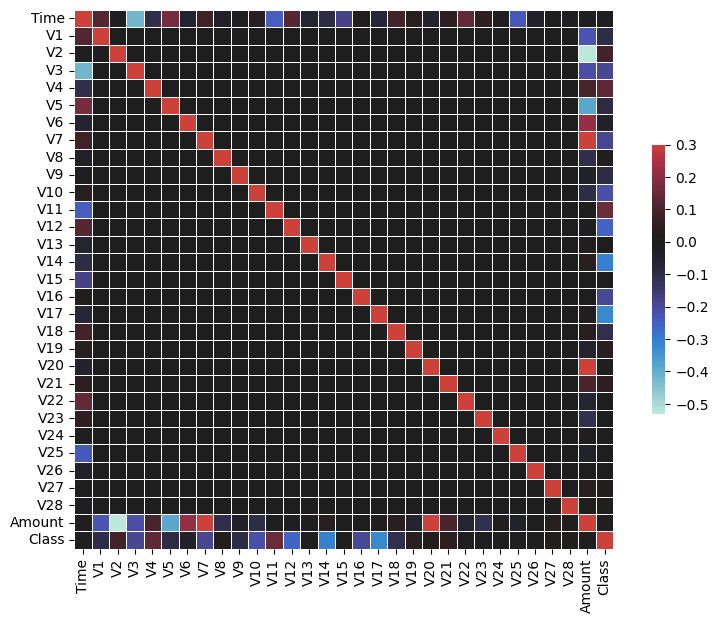

In [12]:
plt.figure(figsize=(10,7))

# Draw the heatmap with the mask and correct aspect ratio
sns.heatmap(df.corr(), vmax=.3, center=0,
            square=True, linewidths=.5, cbar_kws={"shrink": .5})

In [13]:
## checking correlation of 'dependent' variable with each "independent" variable
df.corr()[['Class']].sort_values(by='Class')[:-1]

,Class
V17,-0.326481
V14,-0.302544
V12,-0.260593
V10,-0.216883
V16,-0.196539
V3,-0.192961
V7,-0.187257
V18,-0.111485
V1,-0.101347
V9,-0.097733


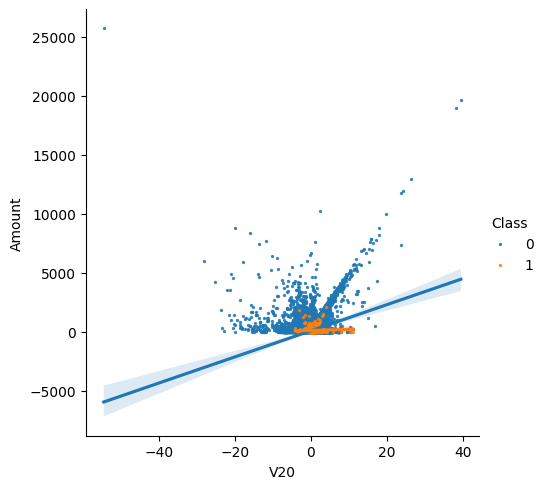

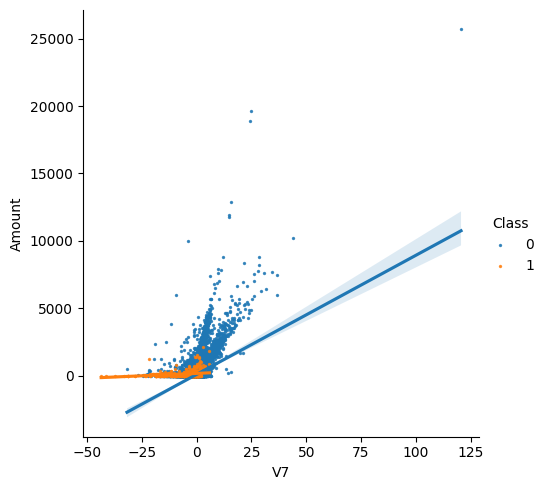

In [14]:
s = sns.lmplot(x='V20', y='Amount',data=df, hue='Class', fit_reg=True,scatter_kws={'s':2})
s = sns.lmplot(x='V7', y='Amount',data=df, hue='Class', fit_reg=True,scatter_kws={'s':2})
plt.show()

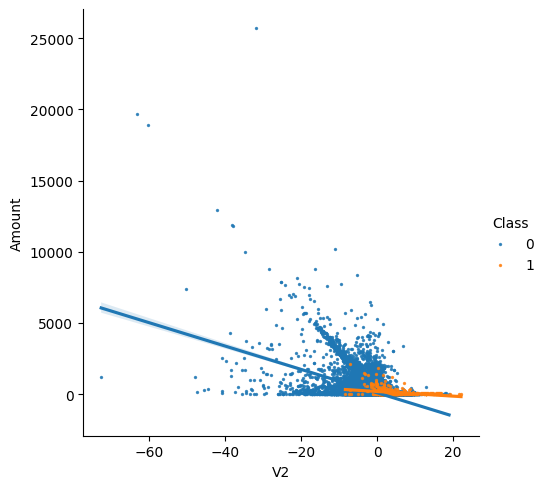

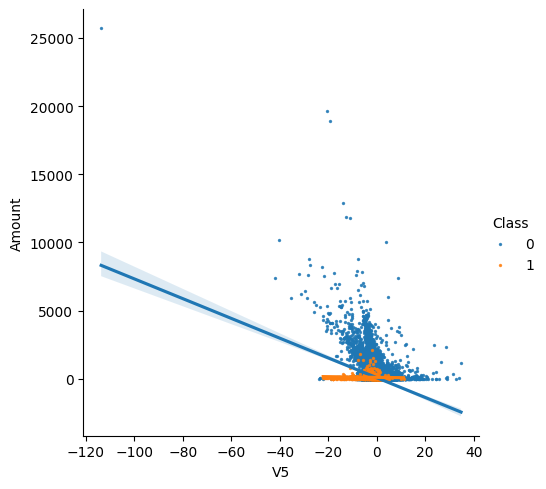

In [15]:
s = sns.lmplot(x='V2', y='Amount',data=df, hue='Class', fit_reg=True,scatter_kws={'s':2})
s = sns.lmplot(x='V5', y='Amount',data=df, hue='Class', fit_reg=True,scatter_kws={'s':2})
plt.show()

We can confirm that the two couples of features are inverse correlated (the regression lines for **Class = 0** have a negative slope while the regression lines for **Class = 1** have a very small negative slope).


C:\Users\fahee\AppData\Local\Temp\ipykernel_19528\2137072470.py:14: UserWarning: 

The `bw` parameter is deprecated in favor of `bw_method` and `bw_adjust`.
Setting `bw_method=0.5`, but please see the docs for the new parameters
and update your code. This will become an error in seaborn v0.13.0.

  sns.kdeplot(t0[feature], bw=0.5,label="Class = 0")
c:\Users\fahee\anaconda3\envs\final\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\fahee\AppData\Local\Temp\ipykernel_19528\2137072470.py:15: UserWarning: 

The `bw` parameter is deprecated in favor of `bw_method` and `bw_adjust`.
Setting `bw_method=0.5`, but please see the docs for the new parameters
and update your code. This will become an error in seaborn v0.13.0.

  sns.kdeplot(t1[feature], bw=0.5,label="Class = 1")
c:\Users\fahee\anacon

<Figure size 640x480 with 0 Axes>

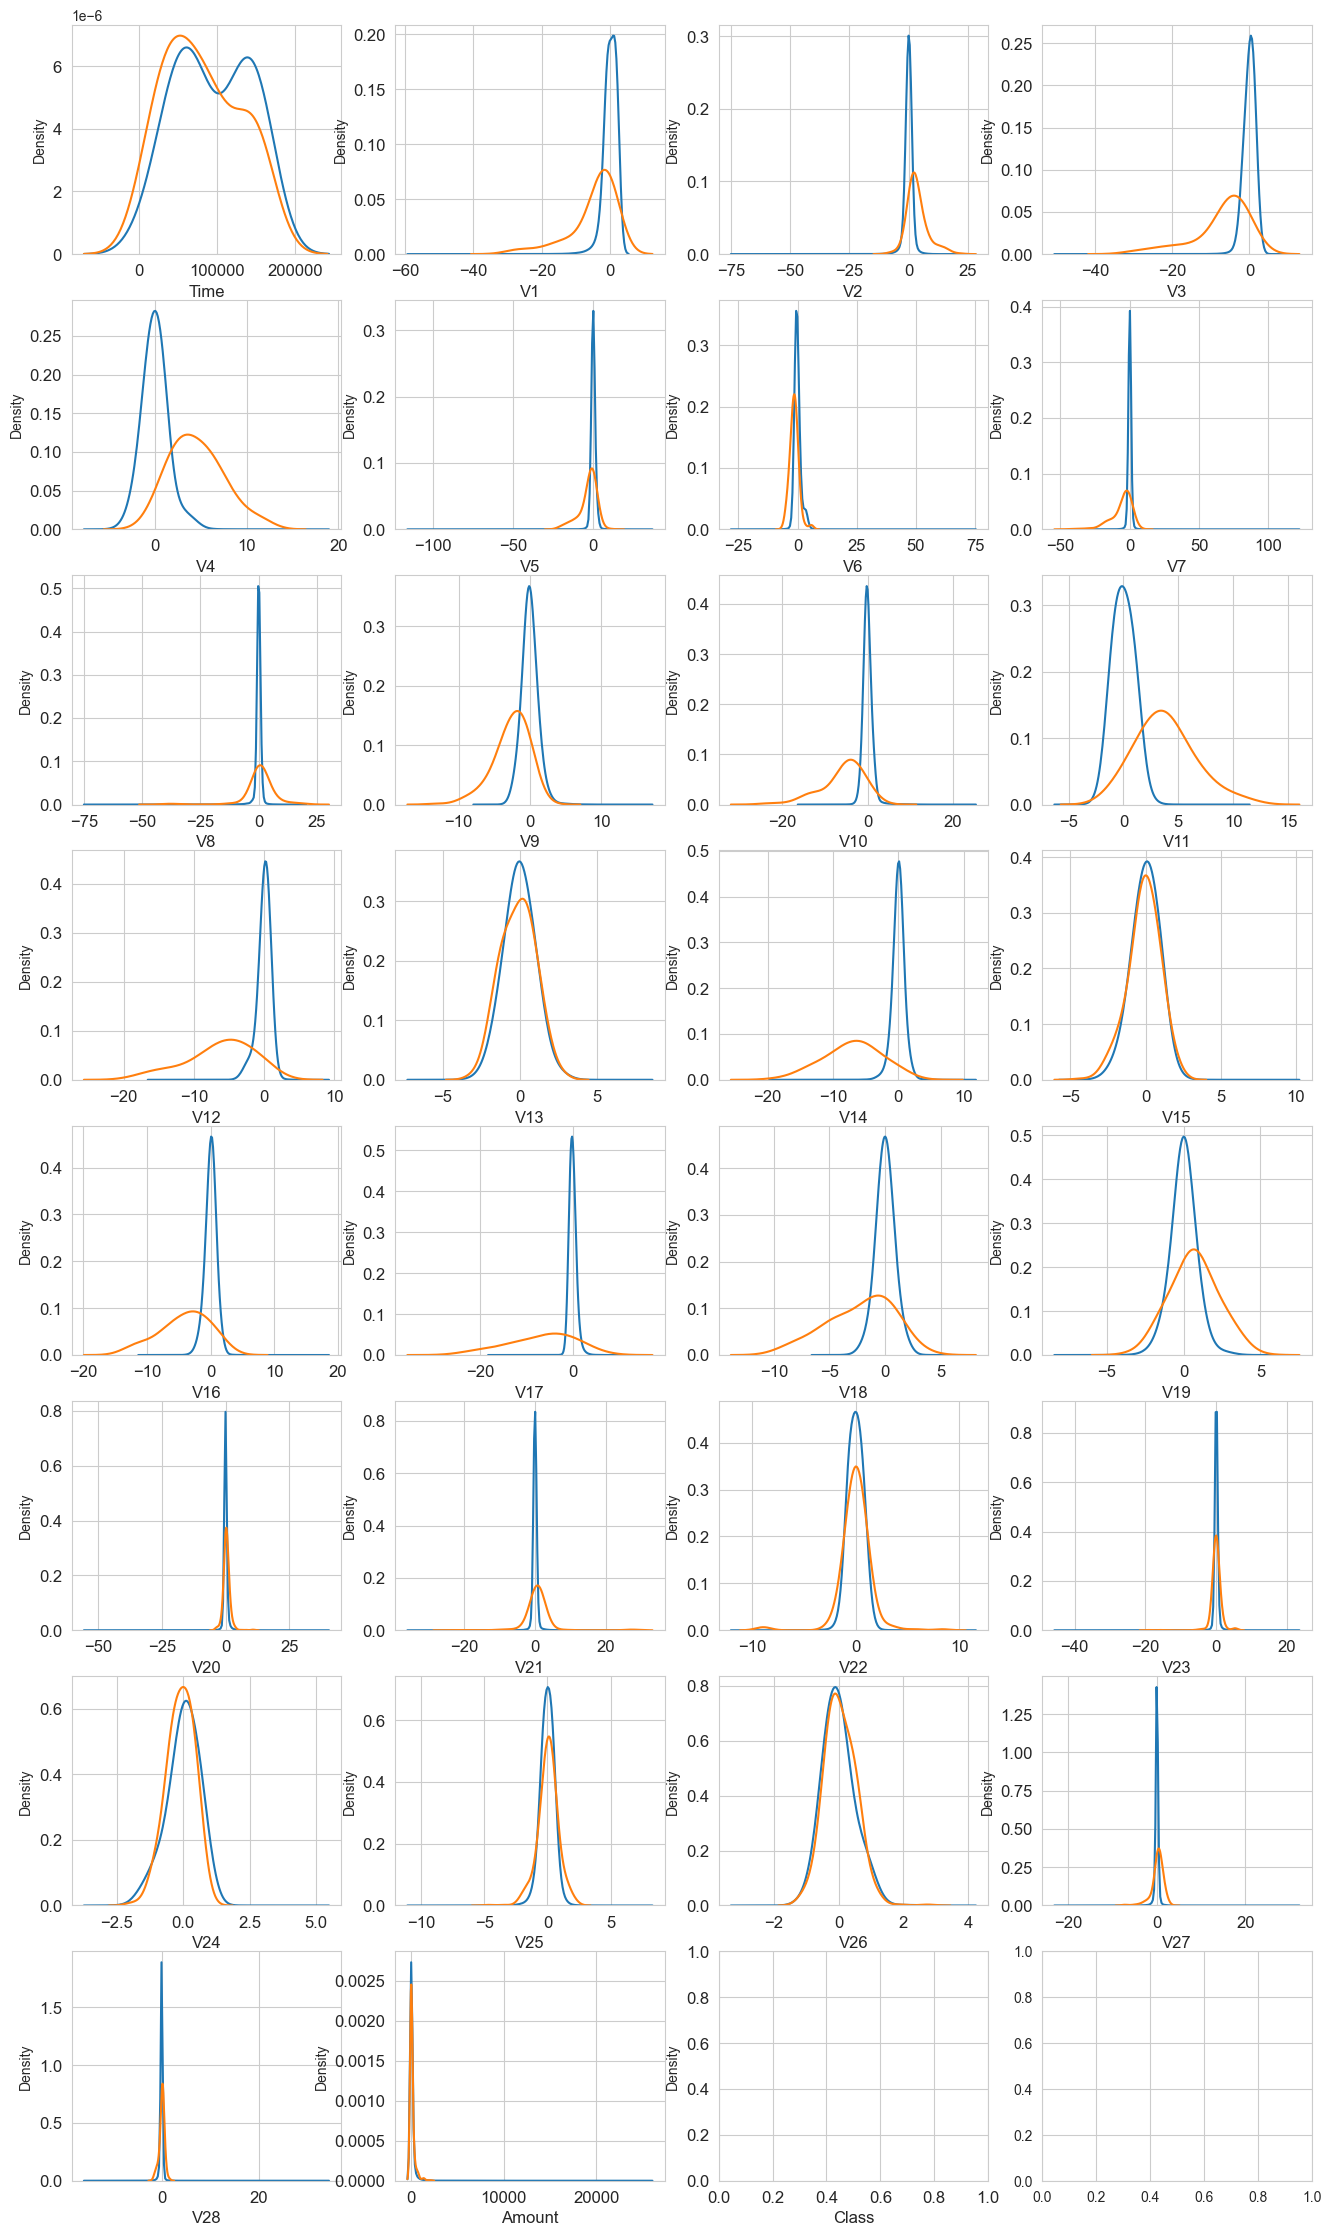

In [16]:
var = df.columns.values

i = 0
t0 = df.loc[df['Class'] == 0]
t1 = df.loc[df['Class'] == 1]

sns.set_style('whitegrid')
plt.figure()
fig, ax = plt.subplots(8,4,figsize=(16,28))

for feature in var:
    i += 1
    plt.subplot(8,4,i)
    sns.kdeplot(t0[feature], bw=0.5,label="Class = 0")
    sns.kdeplot(t1[feature], bw=0.5,label="Class = 1")
    plt.xlabel(feature, fontsize=12)
    locs, labels = plt.xticks()
    plt.tick_params(axis='both', which='major', labelsize=12)
plt.show();

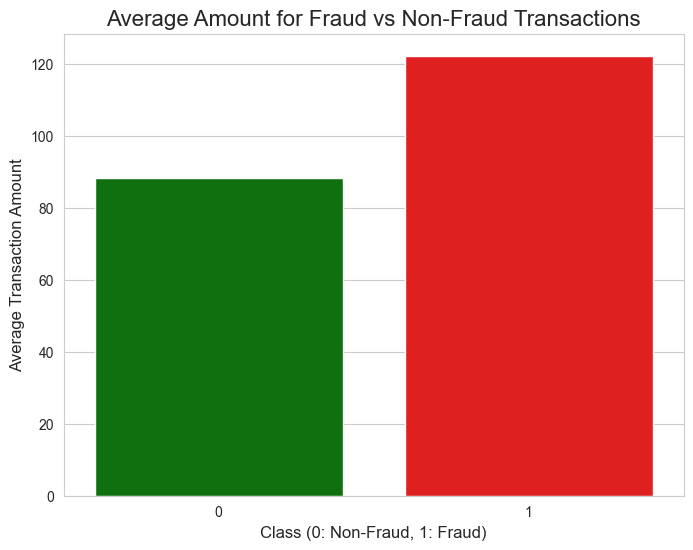

In [17]:
# Bar Plot: Average Amount by Class (Fraud/Non-Fraud)
avg_amount = df.groupby('Class')['Amount'].mean().reset_index()
plt.figure(figsize=(8, 6))
sns.barplot(
    x='Class',
    y='Amount',
    data=avg_amount,
    palette={0: 'green', 1: 'red'}
)
plt.title('Average Amount for Fraud vs Non-Fraud Transactions', fontsize=16)
plt.xlabel('Class (0: Non-Fraud, 1: Fraud)', fontsize=12)
plt.ylabel('Average Transaction Amount', fontsize=12)
plt.show()

c:\Users\fahee\anaconda3\envs\final\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\fahee\anaconda3\envs\final\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


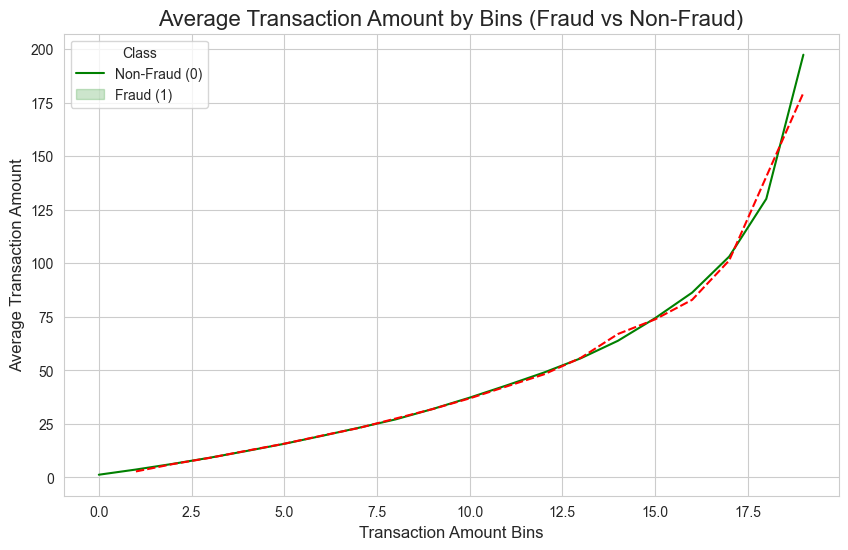

In [18]:

np.random.seed(42)
n = 5000
data = {
    'Amount': np.random.exponential(scale=50, size=n),  # Transaction Amount
    'Class': np.random.choice([0, 1], size=n, p=[0.99, 0.01])  # Fraud (1) vs Non-Fraud (0)
}
df = pd.DataFrame(data)

# Create 'Amount bins' to group the transactions
df['Amount_Bin'] = pd.qcut(df['Amount'], q=20, labels=False)  # Divides into 20 quantile bins

# Group by Amount bins and Class to calculate the average amount
grouped = df.groupby(['Amount_Bin', 'Class'])['Amount'].mean().reset_index()

# Rename the columns for clarity
grouped.columns = ['Amount_Bin', 'Class', 'Average_Amount']

# Create the plot
plt.figure(figsize=(10, 6))
sns.lineplot(
    data=grouped,
    x='Amount_Bin',
    y='Average_Amount',
    hue='Class',
    style='Class',
    palette={0: 'green', 1: 'red'},  
    errorbar='sd'  # Confidence Interval based on Standard Deviation
)

# Customize the graph
plt.title("Average Transaction Amount by Bins (Fraud vs Non-Fraud)", fontsize=16)
plt.xlabel("Transaction Amount Bins", fontsize=12)
plt.ylabel("Average Transaction Amount", fontsize=12)
plt.legend(title="Class", labels=["Non-Fraud (0)", "Fraud (1)"])
plt.grid(True)
plt.show()


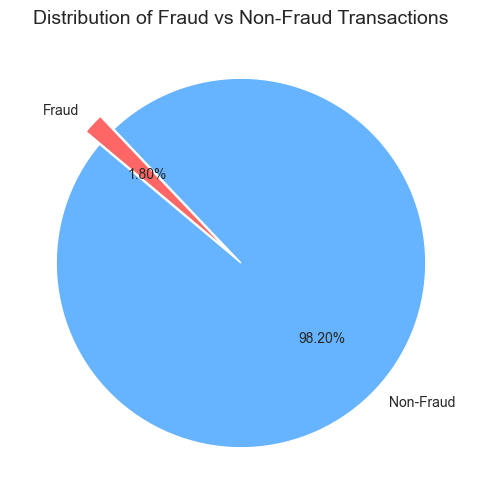

In [19]:
np.random.seed(42)
n = 1000
data = {
    'Class': np.random.choice([0, 1], size=n, p=[0.98, 0.02])  
}
df = pd.DataFrame(data)

class_counts = df['Class'].value_counts()

labels = ['Non-Fraud', 'Fraud']
colors = ['#66b3ff', '#ff6666']  

# Create the pie chart
plt.figure(figsize=(8, 6))
plt.pie(class_counts, labels=labels, autopct='%1.2f%%', startangle=140, colors=colors, explode=[0, 0.1])
plt.title('Distribution of Fraud vs Non-Fraud Transactions', fontsize=14)
plt.show()

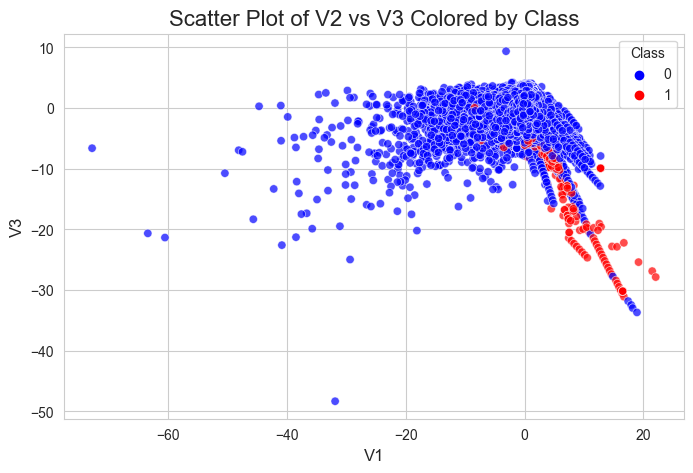

In [23]:
# Scatter Plot for V2 and V3 with Blue and Red Colors
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df, 
    x='V2', 
    y='V3', 
    hue='Class', 
    palette={0: 'blue', 1: 'red'},  # Class 0: Blue, Class 1: Red
    alpha=0.7
)
plt.title("Scatter Plot of V2 vs V3 Colored by Class", fontsize=16)
plt.xlabel("V1", fontsize=12)
plt.ylabel("V3", fontsize=12)
plt.legend(title="Class", loc='upper right')
plt.show()

c:\Users\fahee\anaconda3\envs\final\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\fahee\anaconda3\envs\final\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\fahee\anaconda3\envs\final\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\fahee\anaconda3\envs\final\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version

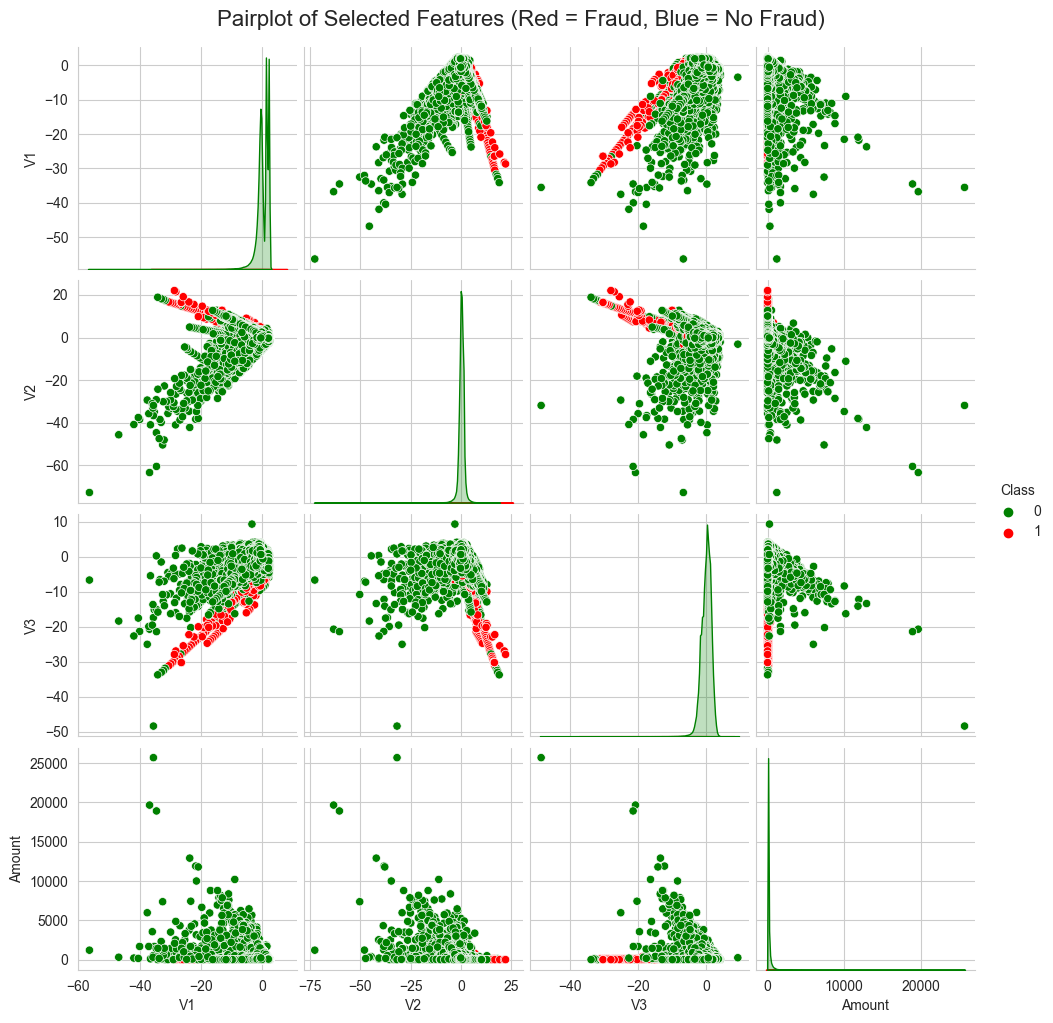

In [24]:
# Select a subset of features for the pairplot
subset_features = ['V1', 'V2', 'V3', 'Amount', 'Class']

# Pairplot with custom red and blue colors for the classes
sns.pairplot(
    df[subset_features], 
    hue='Class', 
    palette={0: 'green', 1: 'red'},  # Class 0: Blue, Class 1: Red
    diag_kind='kde'
)

# Add a title to the plot
plt.suptitle("Pairplot of Selected Features (Red = Fraud, Blue = No Fraud)", y=1.02, fontsize=16)

# Display the plot
plt.show()


## **Build Model By using XGBOOS**

Training XGBoost Model...


c:\Users\fahee\anaconda3\envs\final\lib\site-packages\xgboost\core.py:160: UserWarning: [08:10:00] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-0b3782d1791676daf-1\xgboost\xgboost-ci-windows\src\learner.cc:742: 
Parameters: { "silent" } are not used.

  warnings.warn(smsg, UserWarning)


[0]	train-auc:0.89895	valid-auc:0.90726
[50]	train-auc:0.92305	valid-auc:0.92767
[56]	train-auc:0.94207	valid-auc:0.92544

Evaluating on Test Data...

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     28432
           1       0.87      0.82      0.84        49

    accuracy                           1.00     28481
   macro avg       0.93      0.91      0.92     28481
weighted avg       1.00      1.00      1.00     28481


Confusion Matrix:
[[28426     6]
 [    9    40]]

ROC-AUC Score on Test Data: 0.9671


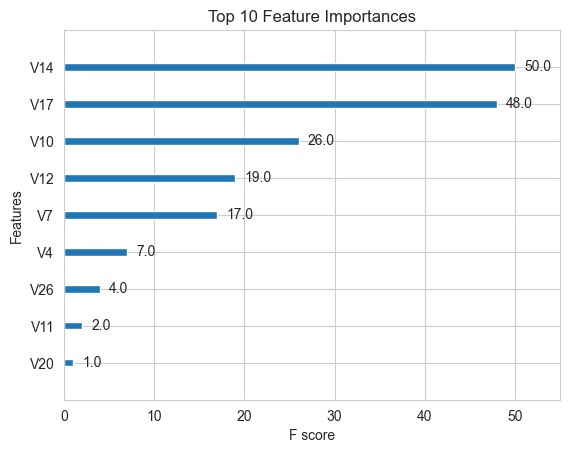

In [25]:
# Define the target and predictors
target = 'Class'
predictors = ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
              'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19',
              'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28',
              'Amount']

# Split data into train, valid, and test sets (80% train, 10% valid, 10% test)
train_df, temp_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df[target])
valid_df, test_df = train_test_split(temp_df, test_size=0.5, random_state=42, stratify=temp_df[target])

# Create DMatrix for XGBoost
dtrain = xgb.DMatrix(train_df[predictors], label=train_df[target].values)
dvalid = xgb.DMatrix(valid_df[predictors], label=valid_df[target].values)
dtest = xgb.DMatrix(test_df[predictors], label=test_df[target].values)

# What to monitor during training
watchlist = [(dtrain, 'train'), (dvalid, 'valid')]

# Set XGBoost parameters
params = {
    'objective': 'binary:logistic',  # Binary classification problem
    'eta': 0.039,                   # Learning rate
    'silent': True,                 # Suppress logs
    'max_depth': 2,                 # Depth of trees
    'subsample': 0.8,               # Row subsampling
    'colsample_bytree': 0.9,        # Column subsampling
    'eval_metric': 'auc',           # Evaluation metric
    'random_state': 42              # Ensure reproducibility
}

# Train the model
print("Training XGBoost Model...")
xgb_model = xgb.train(params, dtrain, num_boost_round=1000, evals=watchlist, 
                      early_stopping_rounds=50, verbose_eval=50)

# Evaluate on test data
print("\nEvaluating on Test Data...")
y_test_pred_proba = xgb_model.predict(dtest)
y_test_pred = [1 if pred > 0.5 else 0 for pred in y_test_pred_proba]

# Print performance metrics
print("\nClassification Report:")
print(classification_report(test_df[target], y_test_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(test_df[target], y_test_pred))

roc_auc = roc_auc_score(test_df[target], y_test_pred_proba)
print(f"\nROC-AUC Score on Test Data: {roc_auc:.4f}")
 
# Feature Importance
xgb.plot_importance(xgb_model, importance_type='weight', max_num_features=10, title="Top 10 Feature Importances")
plt.show()


This code is an end-to-end workflow for training and evaluating a binary classification model using XGBoost. Here's a summary:

1. **Data Preparation:**  - Defines the target variable (`Class`) and the predictor features.  - Splits the data into training (80%), validation (10%), and test (10%) sets, ensuring stratification by the target variable to maintain class distribution.

2. **XGBoost Data Matrix (DMatrix):**  
   - Converts the training, validation, and test sets into `DMatrix` format, which optimizes data storage and processing for XGBoost.  

3. **Model Training:**  
   - Sets XGBoost hyperparameters, including learning rate (`eta`), maximum tree depth (`max_depth`), and evaluation metric (`auc`).
- Utilizes early stopping to halt training when validation performance hasn't improved after 50 rounds.  
   - Checks the training and validation performance during the training process.

4. **Model Evaluation:** 
- Makes probability predictions on the test data and uses these probabilities as binary class predictions with a threshold at 0.5.
- Calculates and prints the main evaluation scores such as classification report, confusion matrix, and ROC-AUC score.

5. **Feature Importance:**
   Shows the top 10 of the most important features given their weight in the XGBoost model.




Confusion Matrix:


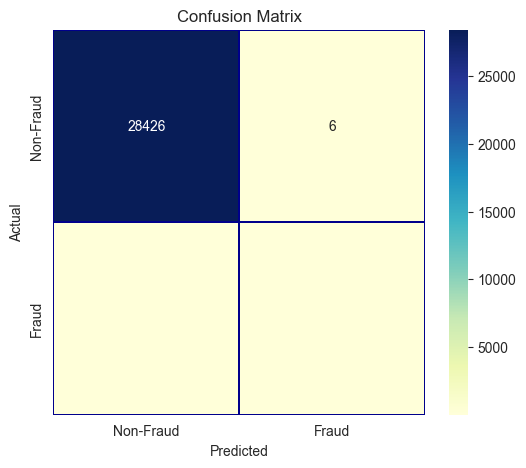


ROC-AUC Score on Test Data: 0.9671


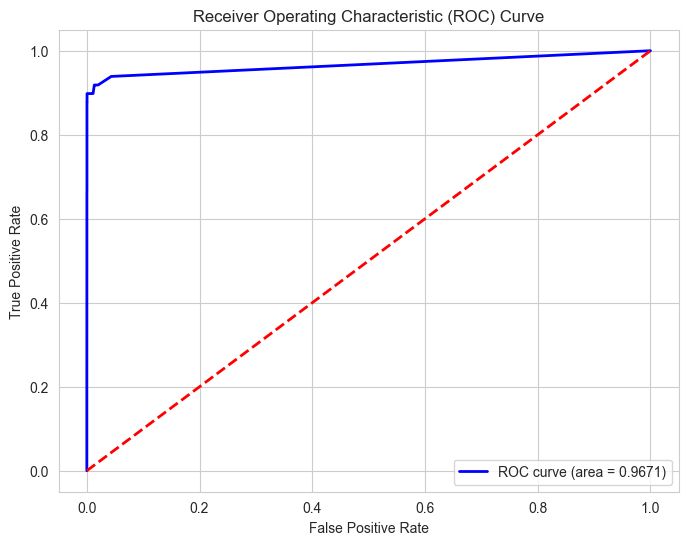

In [28]:

# Confusion Matrix Visualization
def plot_confusion_matrix(y_true, y_pred, labels=["Non-Fraud", "Fraud"]):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="YlGnBu", xticklabels=labels, 
                yticklabels=labels, linewidths=.2, linecolor="Darkblue")  # Added linewidths and linecolor
    plt.title("Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

# ROC-AUC Curve Visualization
def plot_roc_auc(y_true, y_pred_proba):
    fpr, tpr, thresholds = roc_curve(y_true, y_pred_proba)
    roc_auc = auc(fpr, tpr)
    
    plt.figure(figsize=(8, 6))
    plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC curve (area = {roc_auc:.4f})')
    plt.plot([0, 1], [0, 1], color='red', lw=2, linestyle='--')  # Diagonal line
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("Receiver Operating Characteristic (ROC) Curve")
    plt.legend(loc="lower right")
    plt.show()

# Print Metrics
print("\nConfusion Matrix:")
plot_confusion_matrix(test_df[target], y_test_pred)

# ROC-AUC Score and Plot
roc_auc = roc_auc_score(test_df[target], y_test_pred_proba)
print(f"\nROC-AUC Score on Test Data: {roc_auc:.4f}")
plot_roc_auc(test_df[target], y_test_pred_proba)


In [29]:
import joblib

# Save the trained XGBoost model to a file
model_filename = "xgboost_fraud_detection_model.pkl"
joblib.dump(xgb_model, model_filename)

print(f"Model saved as '{model_filename}'")


Model saved as 'xgboost_fraud_detection_model.pkl'


We then experimented with a **XGBoost** model. In this case, se used the validation set for validation of the training model.  The best validation score obtained was   **0.984**. Then we used the model with the best training step, to predict target value from the test data; the AUC score obtained was **0.974**.

In [30]:
preds = xgb_model.predict(dtest)
roc_auc_score(test_df[target].values, preds)

0.9670847306283235

### A Confusion Matrix plot

Provides insights into True Positives, True Negatives, False Positives, and False Negatives.
A ROC-AUC Curve:

Measures the tradeoff between the true positive rate and false positive rate.
The "AUC value" quantifies how well the model distinguishes between fraud and non-fraud.